# Librerie

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ast
from astropy.table import Table
from scipy import stats
from fbm import FBM
from scipy.stats import normaltest, ks_2samp, ttest_ind, zscore
from scipy.stats import kurtosis

# Dati

In [2]:
df = Table.read("DATA_TRACK_B.csv")

In [3]:
strain = df["strain"]
l = df["l"]
w = df["w"]
ttraj = df["ttraj"]
xtraj = df["xtraj"]
ytraj = df["ytraj"]

## Dati traiettorie -> array

In [4]:
for i in range(0, len(ytraj)):
    ttraj[i] = ttraj[i][1:-1]
    xtraj[i] = xtraj[i][1:-1]
    ytraj[i] = ytraj[i][1:-1]

In [5]:
t_bid = []

t_bid.append(np.array(ttraj[i].split(", "), dtype=float))
x_bid = [dato.split(", ") for dato in xtraj]
y_bid = [dato.split(", ") for dato in ytraj]

In [6]:
t_array = np.array(t_bid, dtype=np.float64)
x_array = np.array(x_bid, dtype=np.float64)
y_array = np.array(y_bid, dtype=np.float64)

Normalizzo al centro

In [7]:
x_first = x_array[:,0]
y_first = y_array[:,0]

x_array = x_array - x_first[:, np.newaxis]
y_array = y_array - y_first[:, np.newaxis]

Separo per strain (ori e ter)

In [8]:
ori_mask = strain == 'EO'
ter_mask = strain == 'ET'

x_ori = x_array[ori_mask]
y_ori = y_array[ori_mask]

x_ter = x_array[ter_mask]
y_ter = y_array[ter_mask]

# Funzioni

## Mean Squared Displacement

In [9]:
def calculate_msd(x, y):
    n_p, n_t = x.shape
    msd = np.zeros(n_t - 1)

    for i in range(n_p):
        xi = x[i]
        yi = y[i]

        for t in range(1, n_t):
            dx = xi[t] - xi[0]
            dy = yi[t] - yi[0]
            msd[t - 1] += dx**2 + dy**2

    msd /= n_p
    return msd

## Esponenti di diffusione

In [179]:
def estimate_alpha(msd):
    t = np.arange(1, len(msd)+1)
    mask = msd > 0
    log_t = np.log(t[mask])
    log_msd = np.log(msd[mask])
    slope, _ = np.polyfit(log_t, log_msd, 1)
    return slope

## MSD temporale

In [11]:
def time_averaged_msd(x, y):
    n_t = x.shape[1]
    msds = []

    for i in range(x.shape[0]):
        msd_i = []
        for tau in range(1, n_t):
            displacements = (x[i, tau:] - x[i, :-tau])**2 + (y[i, tau:] - y[i, :-tau])**2
            msd_i.append(np.mean(displacements))
        msds.append(msd_i)
    
    return np.array(msds)

## Calcolo dislpacements per intervalli di tempo fissi

In [12]:
def calcola_spostamenti(x, y, delta_t):
    dx = x[:, delta_t:] - x[:, :-delta_t]
    dy = y[:, delta_t:] - y[:, :-delta_t]
    spostamenti = np.sqrt(dx**2 + dy**2)
    return spostamenti.flatten()

## Filtro per traiettorie

In [270]:
def filter_traj(x, y, alpha, alpha_min, alpha_max):
    x_clean = []
    y_clean = []
    x_an = []
    y_an = []

    for i in range(alpha.shape[0]):
        if (alpha_min <= alpha[i] <= alpha_max):
            x_clean.append(x[i])
            y_clean.append(y[i])
        else:
            x_an.append(x[i])
            y_an.append(y[i])

    x_clean = np.array(x_clean)
    y_clean = np.array(y_clean)
    x_an = np.array(x_an)
    y_an = np.array(y_an)

    return x_clean, y_clean, x_an, y_an

In [271]:
x_clean, y_clean, x_an, y_an = filter_traj(x_real_z, y_real_z, alpha_real, alpha_fbm_mean - 1 * alpha_fbm_std, alpha_fbm_mean + 1 * alpha_fbm_std)

In [272]:
x_clean_ori, y_clean_ori, x_an_ori, y_an_ori = filter_traj(x_real_z_ori, y_real_z_ori, alpha_ori, alpha_fbm_mean - 3 * alpha_fbm_std, alpha_fbm_mean + 3 * alpha_fbm_std)
x_clean_ter, y_clean_ter, x_an_ter, y_an_ter = filter_traj(x_real_z_ter, y_real_z_ter, alpha_ter, alpha_fbm_mean - 3 * alpha_fbm_std, alpha_fbm_mean + 3 * alpha_fbm_std)

In [254]:
print(f"Le traiettorie anomale sono il {100 - (x_clean.shape[0]/x_real_z.shape[0])*100:.2f}%, quelle Ori il {100 - (x_clean_ori.shape[0]/x_real_z_ori.shape[0])*100:.2f}% e quelle Ter il {100 - (x_clean_ter.shape[0]/x_real_z_ter.shape[0])*100:.2f}%")

Le traiettorie anomale sono il 0.47%, quelle Ori il 0.83% e quelle Ter il 0.29%


In [266]:
msd_clean = calculate_msd(x_clean, y_clean)

alpha_clean = estimate_alpha(msd_clean)

x_fbm_clean, y_fbm_clean = simulate_fbm_trajectories(len(msd_clean), alpha_clean/2)
x_ctrw_clean, y_ctrw_clean = simulate_CTRW(len(msd_clean), alpha_clean)

x_fbm_clean_z = zscore(x_fbm_clean, axis=1)
y_fbm_clean_z = zscore(y_fbm_clean, axis=1)
x_ctrw_clean_z = zscore(x_ctrw_clean, axis=1)
y_ctrw_clean_z = zscore(y_ctrw_clean, axis=1)


msd_fbm_clean = calculate_msd(x_fbm_clean_z, y_fbm_clean_z)
msd_ctrw_clean = calculate_msd(x_ctrw_clean_z, y_ctrw_clean_z)

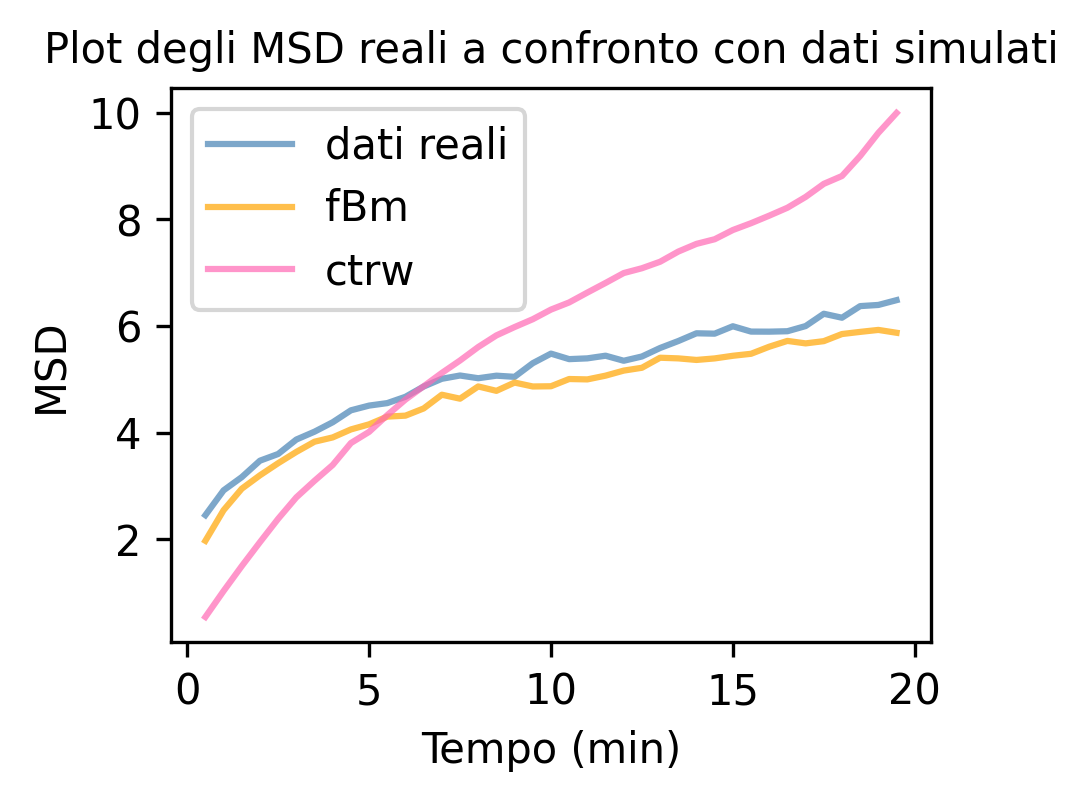

In [267]:
plt.figure(figsize=(3.27, 2.4), dpi=300)

plt.plot(t_array[0, 1:], msd_clean, alpha=0.7, color='steelblue', label='dati reali')
plt.plot(t_array[0, 1:], msd_fbm_norm, alpha=0.7, color='orange', label='fBm')
plt.plot(t_array[0, 1:], msd_ctrw_norm, alpha=0.7, color='hotpink', label='ctrw')

plt.xlabel('Tempo (min)', fontsize=10)
plt.ylabel('MSD', fontsize=10)
plt.title('Plot degli MSD reali a confronto con dati simulati', fontsize=10)
plt.legend(fontsize=10)
plt.show()

In [293]:
msd_an = []
for i in range(x_an.shape[0]):
    msd = calculate_msd(x_an[i:i+1], y_an[i:i+1])
    msd_an.append(msd)

msd_an = np.array(msd_an)

msd_all_clean = []
for i in range(x_clean.shape[0]):
    msd = calculate_msd(x_clean[i:i+1], y_clean[i:i+1])
    msd_all_clean.append(msd)

msd_all_clean = np.array(msd_all_clean)


# Simulazioni

## Fractional brownian motion

In [98]:
def simulate_fbm_trajectories(n_particles, hurst, n_steps=40, length=1.0,
                               random_seed=42, initial_position_range=1.0):
    np.random.seed(random_seed)

    x = np.zeros((n_particles, n_steps))
    y = np.zeros((n_particles, n_steps))

    for i in range(n_particles):
        f_x = FBM(n=n_steps-1, hurst=hurst, length=length, method='daviesharte')
        f_y = FBM(n=n_steps-1, hurst=hurst, length=length, method='daviesharte')

        fbm_x = f_x.fbm()
        fbm_y = f_y.fbm()

        init_x = np.random.uniform(-initial_position_range, initial_position_range)
        init_y = np.random.uniform(-initial_position_range, initial_position_range)

        x[i] = fbm_x + init_x
        y[i] = fbm_y + init_y

        x[i, 0] = init_x
        y[i, 0] = init_y

    return x, y

## Continuos Time Random-Walk

In [99]:
def simulate_CTRW(n_particles, alpha, n_steps=40, step_scale=1.0):
    x = np.zeros((n_particles, n_steps))
    y = np.zeros((n_particles, n_steps))

    for i in range(n_particles):
        positions_x = [0]
        positions_y = [0]

        for _ in range(1, n_steps):
            dx, dy = np.random.normal(0, step_scale, 2)

            positions_x.append(positions_x[-1] + np.sqrt(2*alpha)*dx)
            positions_y.append(positions_y[-1] + np.sqrt(2*alpha)*dy)

        x[i] = positions_x
        y[i] = positions_y

    return np.array(x), np.array(y)

In [100]:
x_fbm_all, y_fbm_all = simulate_fbm_trajectories(len(all_msd), md_slope/2)
x_fbm_ori, y_fbm_ori = simulate_fbm_trajectories(len(ori_msd), md_slope_ori/2)
x_fbm_ter, y_fbm_ter = simulate_fbm_trajectories(len(ter_msd), md_slope_ter/2)

In [101]:
x_ctrw_all, y_ctrw_all = simulate_CTRW(len(all_msd), md_slope)
x_ctrw_ori, y_ctrw_ori = simulate_CTRW(len(ori_msd), md_slope_ori)
x_ctrw_ter, y_ctrw_ter = simulate_CTRW(len(ter_msd), md_slope_ter)

# Codice Vero

## Pareti cellulari

In [102]:
length = np.mean(l)
width = np.mean(w)

cell_x = [-length/2, length/2, length/2, -length/2, -length/2]
cell_y = [-width/2, -width/2, width/2, width/2, -width/2]

length_ori = np.mean(l[ori_mask])
width_ori = np.mean(w[ori_mask])

cell_x_ori = [-length_ori/2, length_ori/2, length_ori/2, -length_ori/2, -length_ori/2]
cell_y_ori = [-width_ori/2, -width_ori/2, width_ori/2, width_ori/2, -width_ori/2]

length_ter = np.mean(l[ter_mask])
width_ter = np.mean(w[ter_mask])

cell_x_ter = [-length_ter/2, length_ter/2, length_ter/2, -length_ter/2, -length_ter/2]
cell_y_ter = [-width_ter/2, -width_ter/2, width_ter/2, width_ter/2, -width_ter/2]

## MSD normalizzato

### Normalizzazione traiettorie

In [103]:
x_real_z = zscore(x_array, axis=1)
x_real_z_ori = zscore(x_ori, axis=1)
x_real_z_ter = zscore(x_ter, axis=1)

y_real_z = zscore(y_array, axis=1)
y_real_z_ori = zscore(y_ori, axis=1)
y_real_z_ter = zscore(y_ter, axis=1)

x_fbm_z = zscore(x_fbm_all, axis=1)
x_fbm_z_ori = zscore(x_fbm_ori, axis=1)
x_fbm_z_ter = zscore(x_fbm_ter, axis=1)

y_fbm_z = zscore(y_fbm_all, axis=1)
y_fbm_z_ori = zscore(y_fbm_ori, axis=1)
y_fbm_z_ter = zscore(y_fbm_ter, axis=1)

x_ctrw_z = zscore(x_ctrw_all, axis=1)
x_ctrw_z_ori = zscore(x_ctrw_ori, axis=1)
x_ctrw_z_ter = zscore(x_ctrw_ter, axis=1)

y_ctrw_z = zscore(y_ctrw_all, axis=1)
y_ctrw_z_ori = zscore(y_ctrw_ori, axis=1)
y_ctrw_z_ter = zscore(y_ctrw_ter, axis=1)

### Calcolo MSD

In [104]:
msd_real_norm = calculate_msd(x_real_z, y_real_z)
msd_real_norm_ori = calculate_msd(x_real_z_ori, y_real_z_ori)
msd_real_norm_ter = calculate_msd(x_real_z_ter, y_real_z_ter)

msd_fbm_norm = calculate_msd(x_fbm_z, y_fbm_z)
msd_fbm_norm_ori = calculate_msd(x_fbm_z_ori, y_fbm_z_ori)
msd_fbm_norm_ter = calculate_msd(x_fbm_z_ter, y_fbm_z_ter)

msd_ctrw_norm = calculate_msd(x_ctrw_z, y_ctrw_z)
msd_ctrw_norm_ori = calculate_msd(x_ctrw_z_ori, y_ctrw_z_ori)
msd_ctrw_norm_ter = calculate_msd(x_ctrw_z_ter, y_ctrw_z_ter)

Media MSD

In [69]:
msd_real_norm_mean = np.mean(msd_real_norm, axis=0)
msd_real_norm_mean_ori = np.mean(msd_real_norm_ori, axis=0)
msd_real_norm_mean_ter = np.mean(msd_real_norm_ter, axis=0)

msd_fbm_norm_mean = np.mean(msd_fbm_norm, axis=0)
msd_fbm_norm_mean_ori = np.mean(msd_fbm_norm_ori, axis=0)
msd_fbm_norm_mean_ter = np.mean(msd_fbm_norm_ter, axis=0)

msd_ctrw_norm_mean = np.mean(msd_ctrw_norm, axis=0)
msd_ctrw_norm_mean_ori = np.mean(msd_ctrw_norm_ori, axis=0)
msd_ctrw_norm_mean_ter = np.mean(msd_ctrw_norm_ter, axis=0)

STD degli MSD

In [70]:
msd_real_norm_std = np.std(msd_real_norm)
msd_real_norm_std_ori = np.std(msd_real_norm_ori)
msd_real_norm_std_ter = np.std(msd_real_norm_ter)

msd_fbm_norm_std = np.std(msd_fbm_norm)
msd_fbm_norm_std_ori = np.std(msd_fbm_norm_ori)
msd_fbm_norm_std_ter = np.std(msd_fbm_norm_ter)

msd_ctrw_norm_std = np.std(msd_ctrw_norm)
msd_ctrw_norm_std_ori = np.std(msd_ctrw_norm_ori)
msd_ctrw_norm_std_ter = np.std(msd_ctrw_norm_ter)

SEM degli MSD

In [71]:
msd_real_norm_sem = msd_real_norm_std / np.sqrt(msd_real_norm.shape[0])
msd_real_norm_sem_ori = msd_real_norm_std_ori / np.sqrt(msd_real_norm_ori.shape[0])
msd_real_norm_sem_ter = msd_real_norm_std_ter / np.sqrt(msd_real_norm_ter.shape[0])

msd_fbm_norm_sem = msd_fbm_norm_std / np.sqrt(msd_fbm_norm.shape[0])
msd_fbm_norm_sem_ori = msd_fbm_norm_std_ori / np.sqrt(msd_fbm_norm_ori.shape[0])
msd_fbm_norm_sem_ter = msd_fbm_norm_std_ter / np.sqrt(msd_fbm_norm_ter.shape[0])

msd_ctrw_norm_sem = msd_ctrw_norm_std / np.sqrt(msd_ctrw_norm.shape[0])
msd_ctrw_norm_sem_ori = msd_ctrw_norm_std_ori / np.sqrt(msd_ctrw_norm_ori.shape[0])
msd_ctrw_norm_sem_ter = msd_ctrw_norm_std_ter / np.sqrt(msd_ctrw_norm_ter.shape[0])

### MSD per traiettorie anomale

In [72]:
all_msd_norm = []
for i in range(x_real_z.shape[0]):
    msd = calculate_msd(x_real_z[i:i+1], y_real_z[i:i+1])
    all_msd_norm.append(msd)

all_msd_norm = np.array(all_msd_norm)

In [73]:
ori_msd_norm = []
for i in range(x_real_z_ori.shape[0]):
    msd = calculate_msd(x_real_z_ori[i:i+1], y_real_z_ori[i:i+1])
    ori_msd_norm.append(msd)

ori_msd_norm = np.array(ori_msd_norm)

In [74]:
ter_msd_norm = []
for i in range(x_real_z_ter.shape[0]):
    msd = calculate_msd(x_real_z_ter[i:i+1], y_real_z_ter[i:i+1])
    ter_msd_norm.append(msd)

ter_msd_norm = np.array(ter_msd_norm)

In [75]:
all_fbm_msd_norm = []
for i in range(x_real_z.shape[0]):
    msd = calculate_msd(x_fbm_z[i:i+1], y_fbm_z[i:i+1])
    all_fbm_msd_norm.append(msd)

all_fbm_msd_norm = np.array(all_fbm_msd_norm)

Limiti entro 5$\sigma$

In [76]:
fbm_upper = msd_fbm_norm_mean + 5 * msd_fbm_norm_std
fbm_lower = msd_fbm_norm_mean - 5 * msd_fbm_norm_std

In [77]:
anomali_fbm_idx = np.where(
    (all_msd_norm > fbm_upper).any(axis=1) |
    (all_msd_norm < fbm_lower).any(axis=1)
)[0]

print(f"Trovate {len(anomali_fbm_idx)} traiettorie non simili a FBM su {len(all_msd_norm)}")

Trovate 2230 traiettorie non simili a FBM su 2547


## MSD traiettorie

Tutte le traiettorie

In [78]:
all_msd = []
for i in range(x_array.shape[0]):
    msd = calculate_msd(x_array[i:i+1], y_array[i:i+1])
    all_msd.append(msd)

all_msd = np.array(all_msd)

mean_msd = np.mean(all_msd, axis=0)
std_msd = np.std(all_msd)
sem_msd = std_msd / np.sqrt(all_msd.shape[0])

Per strain Ori

In [79]:
ori_msd = []
for i in range(x_ori.shape[0]):
    msd = calculate_msd(x_ori[i:i+1], y_ori[i:i+1])
    ori_msd.append(msd)

ori_msd = np.array(ori_msd)

mean_ori_msd = np.mean(ori_msd, axis=0)
std_ori_msd = np.std(ori_msd)
sem_ori_msd = std_ori_msd / np.sqrt(ori_msd.shape[0])

Per strain Ter

In [80]:
ter_msd = []
for i in range(x_ter.shape[0]):
    msd = calculate_msd(x_ter[i:i+1], y_ter[i:i+1])
    ter_msd.append(msd)

ter_msd = np.array(ter_msd)

mean_ter_msd = np.mean(ter_msd, axis=0)
std_ter_msd = np.std(ter_msd)
sem_ter_msd = std_ter_msd / np.sqrt(ter_msd.shape[0])

#### Regressione lineare in scala log-log

In [81]:
taus = t_array[0,1:]
log_taus = np.log(taus)

log_msd = np.log(mean_msd)
log_ori_msd = np.log(mean_ori_msd)
log_ter_msd = np.log(mean_ter_msd)

md_slope, md_intercept, md_r_value, md_p_value, md_std_err = stats.linregress(log_taus, log_msd)
md_slope_ori, md_intercept_ori, md_r_value_ori, md_p_value_ori, md_std_err_ori = stats.linregress(log_taus, log_ori_msd)
md_slope_ter, md_intercept_ter, md_r_value_ter, md_p_value_ter, md_std_err_ter = stats.linregress(log_taus, log_ter_msd)

In [82]:
threshold_high = mean_msd + 5 * std_msd
threshold_low = mean_msd - 5 * std_msd

anomali_indices = np.where((all_msd > threshold_high).any(axis=1) | 
                           (all_msd < threshold_low).any(axis=1))[0]

print(f"Trovate {len(anomali_indices)} traiettorie anomale su {len(all_msd)} totali, ovvero il {(len(anomali_indices)/len(all_msd))*100}%")

Trovate 48 traiettorie anomale su 2547 totali, ovvero il 1.884570082449941%


In [83]:
threshold_high_ori = mean_ori_msd + 5 * std_ori_msd
threshold_low_ori = mean_ori_msd - 5 * std_ori_msd

anomali_indices_ori = np.where((ori_msd > threshold_high_ori).any(axis=1) | 
                           (ori_msd < threshold_low_ori).any(axis=1))[0]

print(f"Trovate {len(anomali_indices_ori)} traiettorie anomale su {len(ori_msd)} totali, ovvero il {(len(anomali_indices_ori)/len(ori_msd))*100}%")

Trovate 13 traiettorie anomale su 846 totali, ovvero il 1.5366430260047281%


In [84]:
threshold_high_ter = mean_ter_msd + 5 * std_ter_msd
threshold_low_ter = mean_ter_msd - 5 * std_ter_msd

anomali_indices_ter = np.where((ter_msd > threshold_high_ter).any(axis=1) | 
                           (ter_msd < threshold_low_ter).any(axis=1))[0]

print(f"Trovate {len(anomali_indices_ter)} traiettorie anomale su {len(ter_msd)} totali, ovvero il {(len(anomali_indices_ter)/len(ter_msd))*100}%")

Trovate 31 traiettorie anomale su 1701 totali, ovvero il 1.8224573780129336%


## Identificazione traiettorie anome da confronto con fbm - con $\alpha$

Calcolo degli $\alpha$

In [230]:
alpha_real = []
for msd in all_msd_norm:
    alpha_real.append(estimate_alpha(msd))
alpha_real = np.array(alpha_real)

alpha_real_mean = np.mean(alpha_real)
alpha_real_std = np.std(alpha_real)

alpha_ori = []
for msd in ori_msd_norm:
    alpha_ori.append(estimate_alpha(msd))
alpha_ori = np.array(alpha_ori)

alpha_ori_mean = np.mean(alpha_ori)
alpha_ori_std = np.std(alpha_ori)

alpha_ter = []
for msd in ter_msd_norm:
    alpha_ter.append(estimate_alpha(msd))
alpha_ter = np.array(alpha_ter)

alpha_fbm = []
for msd in all_fbm_msd_norm:
    alpha_fbm.append(estimate_alpha(msd))
alpha_fbm = np.array(alpha_fbm)

alpha_fbm_mean = np.mean(alpha_fbm)
alpha_fbm_std = np.std(alpha_fbm)

Individuazione delle traiettorie anomale

In [86]:
anomali_alpha_idx = np.where(
    (alpha_real < alpha_fbm_mean - 3 * alpha_fbm_std) |
    (alpha_real > alpha_fbm_mean + 3 * alpha_fbm_std)
)[0]

anomali_alpha_idx_ori = np.where(
    (alpha_ori < alpha_fbm_mean - 3 * alpha_fbm_std) |
    (alpha_ori > alpha_fbm_mean + 3 * alpha_fbm_std)
)[0]

anomali_alpha_idx_ter = np.where(
    (alpha_ter < alpha_fbm_mean - 3 * alpha_fbm_std) |
    (alpha_ter > alpha_fbm_mean + 3 * alpha_fbm_std)
)[0]

print(f"{len(anomali_alpha_idx)} traiettorie anomale per α su {len(alpha_real)}, ovvero il {(len(anomali_alpha_idx)/len(alpha_real))*100}%")
print(f"{len(anomali_alpha_idx_ori)} traiettorie anomale per α su {len(alpha_ori)}, ovvero il {(len(anomali_alpha_idx_ori)/len(alpha_ori))*100}%")
print(f"{len(anomali_alpha_idx_ter)} traiettorie anomale per α su {len(alpha_ter)}, ovvero il {(len(anomali_alpha_idx_ter)/len(alpha_ter))*100}%")

12 traiettorie anomale per α su 2547, ovvero il 0.47114252061248524%
7 traiettorie anomale per α su 846, ovvero il 0.8274231678486997%
5 traiettorie anomale per α su 1701, ovvero il 0.29394473838918284%


Traiettorie non anomale $\rightarrow$ vettori per plot msd

In [87]:
non_anomali_alpha_idx = np.where(
    (alpha_real >= alpha_fbm_mean - 3 * alpha_fbm_std) &
    (alpha_real <= alpha_fbm_mean + 3 * alpha_fbm_std)
)[0]

non_anomali_alpha_idx_ori = np.where(
    (alpha_ori > alpha_fbm_mean - 3 * alpha_fbm_std) &
    (alpha_ori < alpha_fbm_mean + 3 * alpha_fbm_std)
)[0]

non_anomali_alpha_idx_ter = np.where(
    (alpha_ter > alpha_fbm_mean - 3 * alpha_fbm_std) &
    (alpha_ter < alpha_fbm_mean + 3 * alpha_fbm_std)
)[0]

print(f"{len(non_anomali_alpha_idx)} traiettorie anomale per α su {len(alpha_real)}, ovvero il {(len(non_anomali_alpha_idx)/len(alpha_real))*100}%")
print(f"{len(non_anomali_alpha_idx_ori)} traiettorie anomale per α su {len(alpha_ori)}, ovvero il {(len(non_anomali_alpha_idx_ori)/len(alpha_ori))*100}%")
print(f"{len(non_anomali_alpha_idx_ter)} traiettorie anomale per α su {len(alpha_ter)}, ovvero il {(len(non_anomali_alpha_idx_ter)/len(alpha_ter))*100}%")

2535 traiettorie anomale per α su 2547, ovvero il 99.52885747938751%
839 traiettorie anomale per α su 846, ovvero il 99.17257683215131%
1696 traiettorie anomale per α su 1701, ovvero il 99.70605526161081%


## Distribuzione degli step

In [88]:
dx = x_array[:, 1:] - x_array[:, :-1]
dy = y_array[:, 1:] - y_array[:, :-1]
step_lengths = np.sqrt(dx**2 + dy**2)

step_lengths_flat = step_lengths.flatten()

In [89]:
dx_ori = x_ori[:, 1:] - x_ori[:, :-1]
dy_ori = y_ori[:, 1:] - y_ori[:, :-1]
step_lengths_ori = np.sqrt(dx_ori**2 + dy_ori**2)

step_lengths_flat_ori = step_lengths_ori.flatten()

In [90]:
dx_ter = x_ter[:, 1:] - x_ter[:, :-1]
dy_ter = y_ter[:, 1:] - y_ter[:, :-1]
step_lengths_ter = np.sqrt(dx_ter**2 + dy_ter**2)

step_lengths_flat_ter = step_lengths_ter.flatten()

## Ergodicità

In [91]:
msd_temp_real = time_averaged_msd(x_real_z, y_real_z)

In [92]:
msd_temp_real_mean = np.mean(msd_temp_real, axis=0)
msd_temp_real_std = np.std(msd_temp_real, axis=0)

# Grafici

## MSD

### Plot per tutte le traiettorie

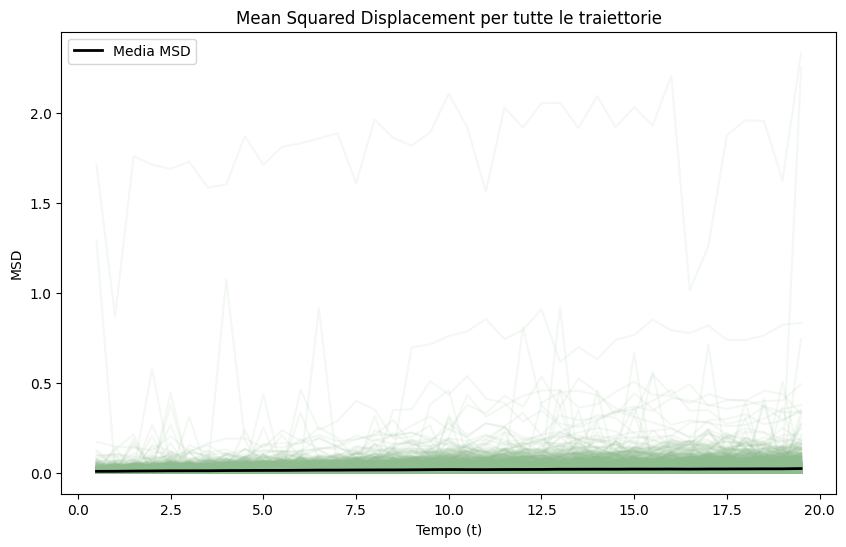

In [51]:
plt.figure(figsize=(10, 6))
for msd in all_msd:
    plt.plot(t_array[0, 1:], msd, alpha=0.1, color='darkseagreen')

plt.plot(t_array[0, 1:], mean_msd, color='black', label='Media MSD', linewidth=2)

plt.xlabel('Tempo (t)')
plt.ylabel('MSD')
plt.title('Mean Squared Displacement per tutte le traiettorie')
plt.legend()
plt.show()

### Adattatemento dei modelli ai dati reali

Ergodicità

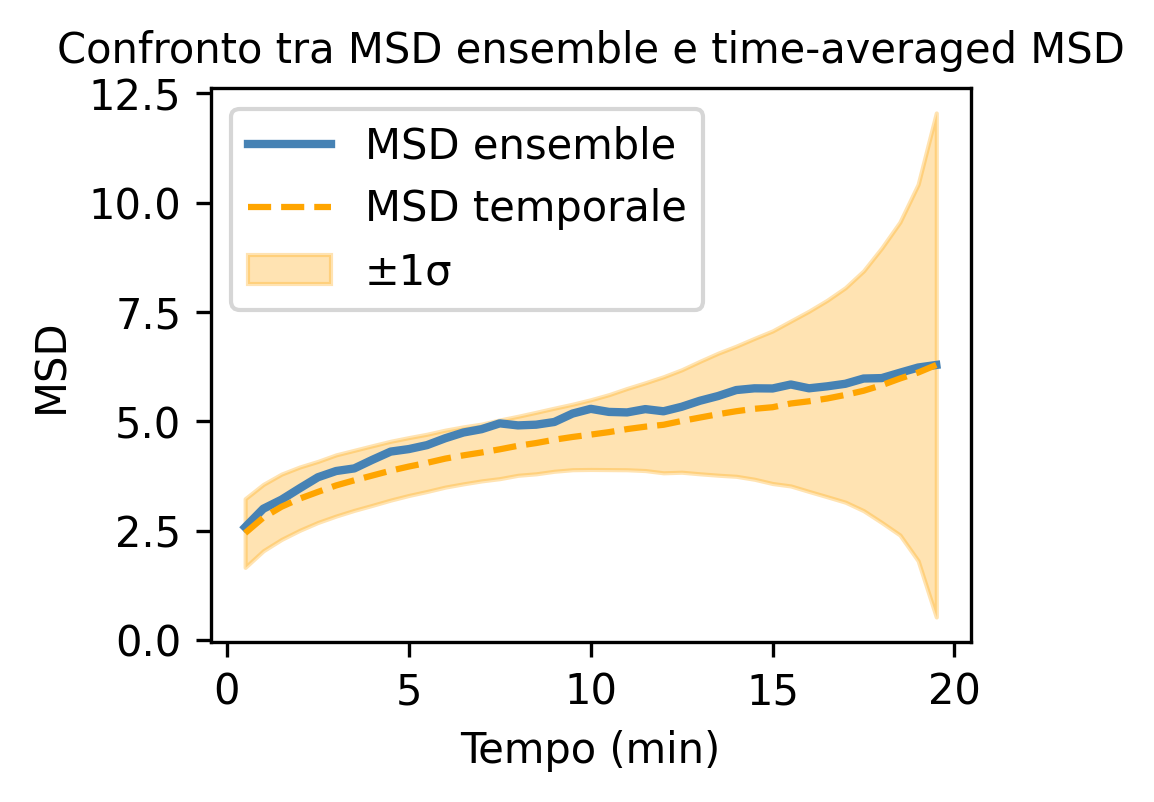

In [174]:
plt.figure(figsize=(3.27, 2.4), dpi=300)
plt.plot(taus, msd_real_norm, label='MSD ensemble', color='steelblue', linewidth=2)
plt.plot(taus, msd_temp_real_mean, label='MSD temporale', color='orange', linestyle='--')
plt.fill_between(taus, 
                 msd_temp_real_mean - msd_temp_real_std, 
                 msd_temp_real_mean + msd_temp_real_std, 
                 color='orange', alpha=0.3, label='±1σ')

plt.xlabel("Tempo (min)", fontsize=10)
plt.ylabel("MSD", fontsize=10)
plt.title("Confronto tra MSD ensemble e time-averaged MSD", fontsize=10)
plt.legend(fontsize=10)
plt.show()

Distribuzione dei displacements

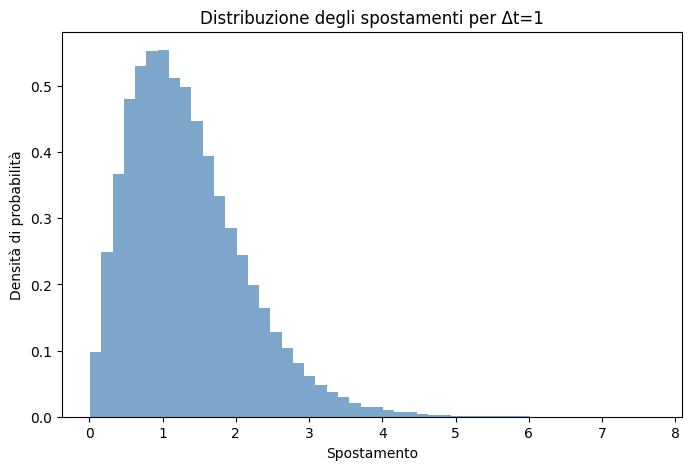

In [165]:
spostamenti = calcola_spostamenti(x_real_z, y_real_z, delta_t=1)

plt.figure(figsize=(8, 5))
plt.hist(spostamenti, bins=50, density=True, alpha=0.7, color='steelblue')
plt.xlabel('Spostamento')
plt.ylabel('Densità di probabilità')
plt.title('Distribuzione degli spostamenti per Δt=1')
plt.show()

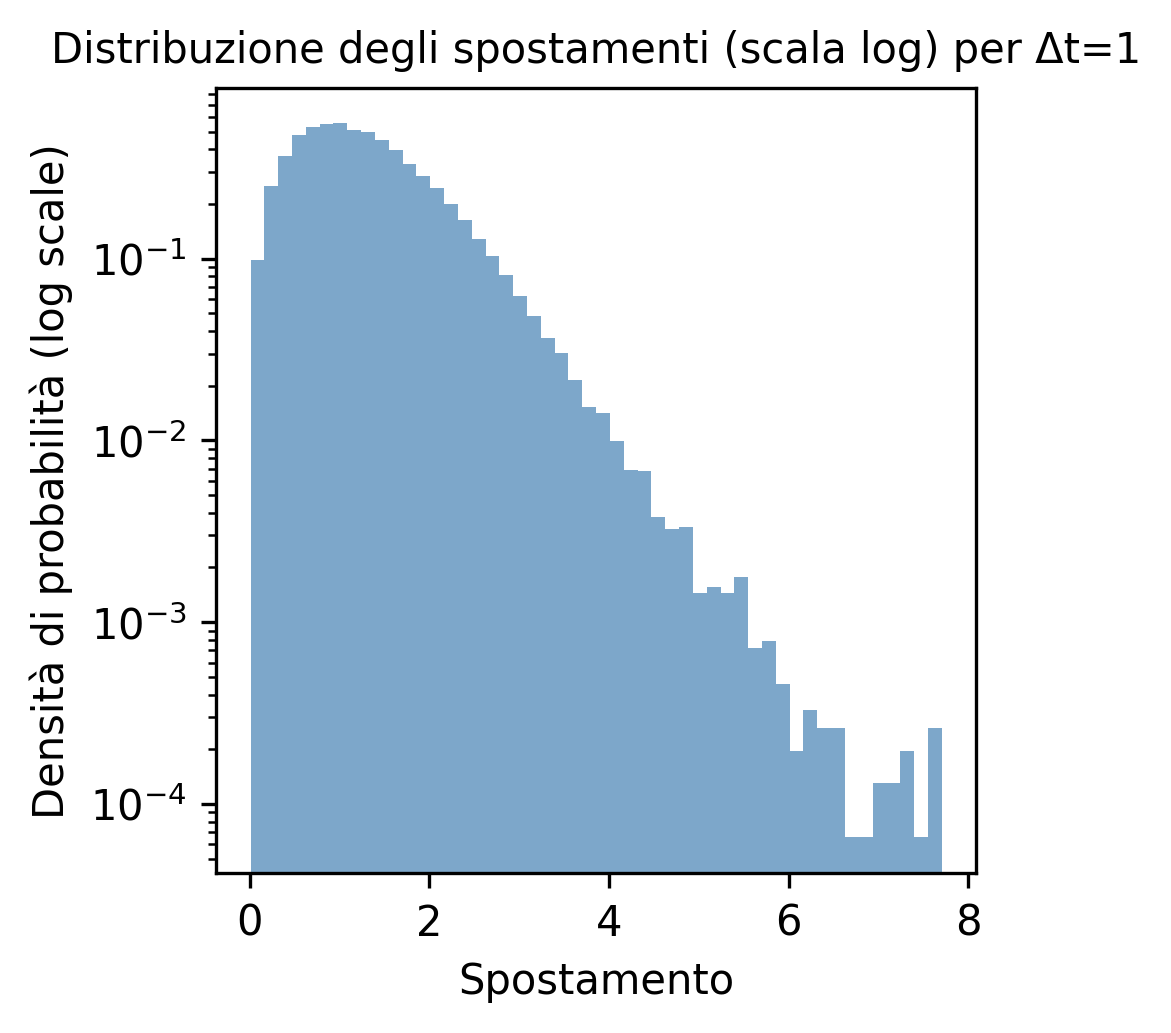

In [175]:
plt.figure(figsize=(3.27, 3.4), dpi=300)
plt.hist(spostamenti, bins=50, density=True, alpha=0.7, color='steelblue', log=True)
plt.xlabel('Spostamento', fontsize=10)
plt.ylabel('Densità di probabilità (log scale)', fontsize=10)
plt.title('Distribuzione degli spostamenti (scala log) per Δt=1', fontsize=10)
plt.show()

Dai confronti vedo che i dati si adattano meglio a un modello fbm

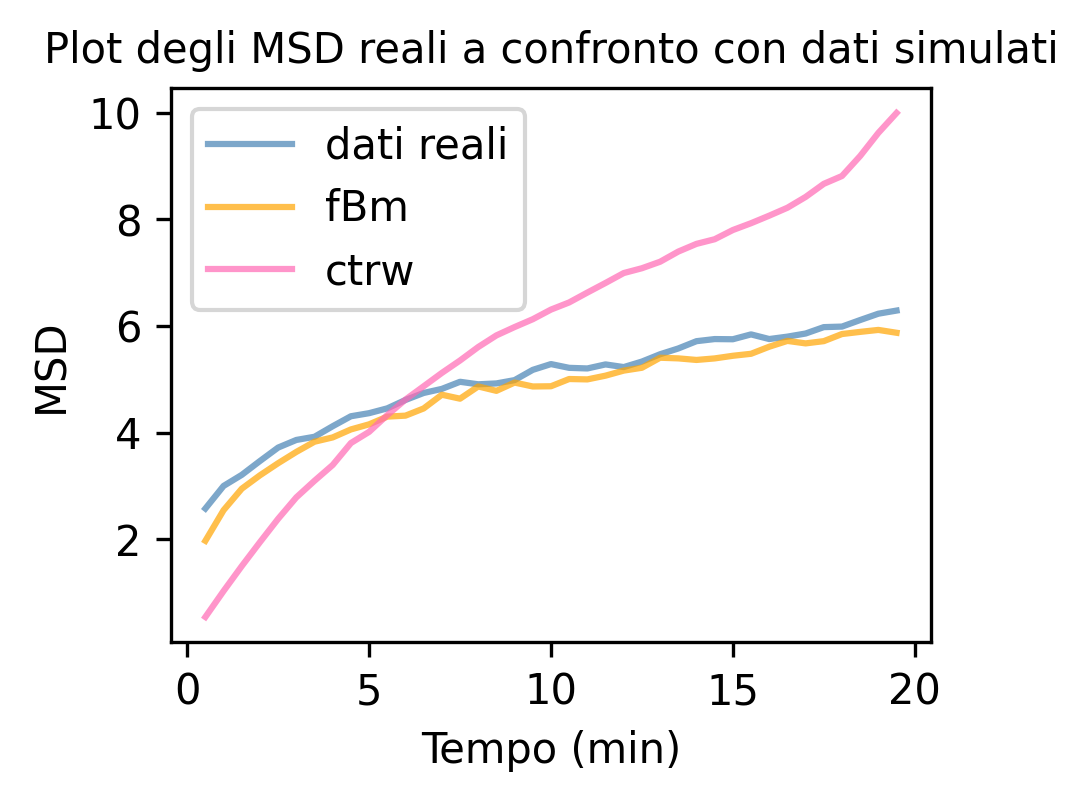

In [176]:
plt.figure(figsize=(3.27, 2.4), dpi=300)

plt.plot(t_array[0, 1:], msd_real_norm, alpha=0.7, color='steelblue', label='dati reali')
plt.plot(t_array[0, 1:], msd_fbm_norm, alpha=0.7, color='orange', label='fBm')
plt.plot(t_array[0, 1:], msd_ctrw_norm, alpha=0.7, color='hotpink', label='ctrw')

plt.xlabel('Tempo (min)', fontsize=10)
plt.ylabel('MSD', fontsize=10)
plt.title('Plot degli MSD reali a confronto con dati simulati', fontsize=10)
plt.legend(fontsize=10)
plt.show()

### Plot msd medio, per tutte le traiettorie e diviso per strain A POSTO

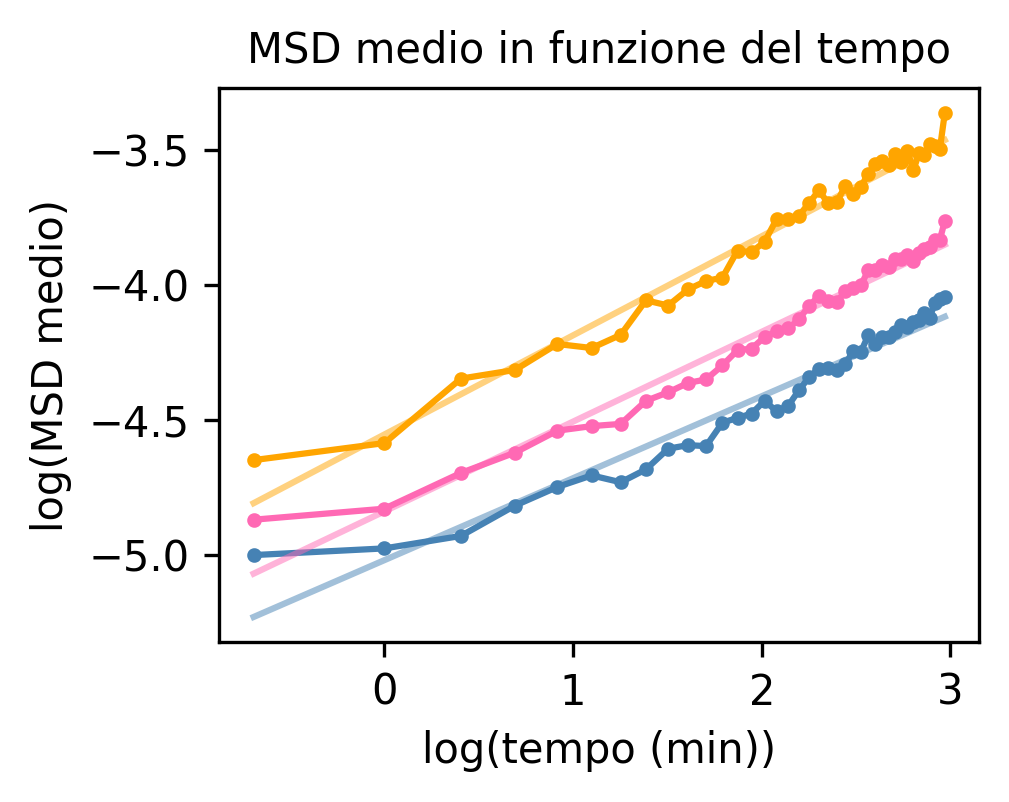

In [178]:
fig, ax = plt.subplots(figsize=(3.27, 2.4), dpi=300)

ax.plot(log_taus, log_msd, color='hotpink', marker='o', label='MSD medio', markersize=2.5)
ax.plot(log_taus, log_ori_msd, color='orange', marker='o', label='MSD medio Ori', markersize=2.5)
ax.plot(log_taus, log_ter_msd, color='steelblue', marker='o', label='MSD medio Ter', markersize=2.5)

ax.plot(log_taus, md_slope * log_taus + md_intercept, color='hotpink', alpha=0.5,
        label=f"Regr. Lin. log(MSD medio) $\\alpha = {md_slope:.2f}$")
ax.plot(log_taus, md_slope_ori * log_taus + md_intercept_ori, color='orange', alpha=0.5,
        label=f"Regr. Lin. log(MSD medio ori) $\\alpha = {md_slope_ori:.2f}$")
ax.plot(log_taus, md_slope_ter * log_taus + md_intercept_ter, color='steelblue', alpha=0.5,
        label=f"Regr. Lin. log(MSD medio ter) $\\alpha = {md_slope_ter:.2f}$")

ax.set_xlabel("log(tempo (min))", fontsize=10)
ax.set_ylabel("log(MSD medio)", fontsize=10)
ax.set_title("MSD medio in funzione del tempo", fontsize=10)

handles, labels = ax.get_legend_handles_labels()

legend_fig = plt.figure(figsize=(3.27, 2.4))
legend_ax = legend_fig.add_subplot(111)
legend_ax.axis('off')

legend = legend_ax.legend(handles, labels, loc='center', fontsize=10)

legend_fig.savefig("legenda_solo.png", dpi=300, bbox_inches='tight', transparent=True)
plt.close(legend_fig)

fig.savefig("grafico_msd.png", dpi=300, bbox_inches='tight')

plt.show()

## Distribuzione degli step

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].hist(step_lengths_flat, bins=300, color='crimson', alpha=0.8, density=True)
axes[1].hist(step_lengths_flat_ori, bins=300, color='gold', alpha=0.8, density=True)
axes[2].hist(step_lengths_flat_ter, bins=300, color='steelblue', alpha=0.8, density=True)
plt.xlabel('Lunghezza dello step')
plt.ylabel('Densità')
plt.title('Distribuzione delle lunghezze degli step')
plt.show()

## Traiettorie anomale - MSD fuori da 5$\sigma$

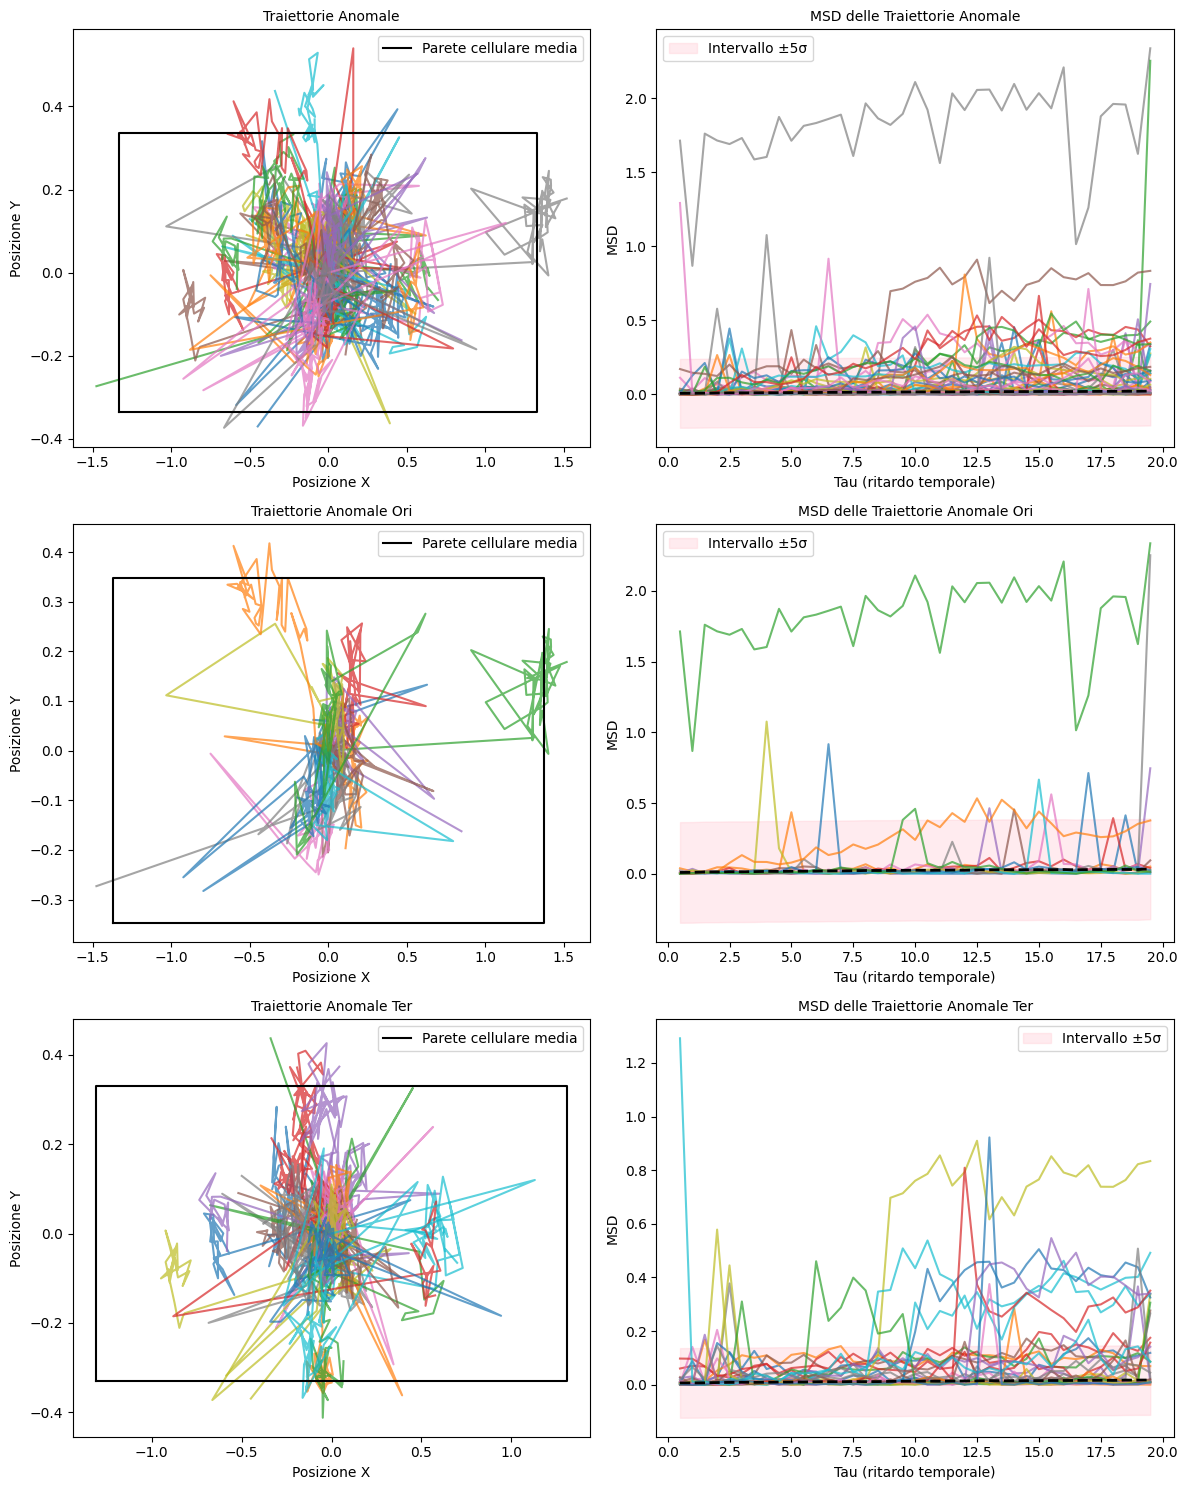

In [161]:
fig, axes = plt.subplots(3, 2, figsize=(12, 15))

for idx in anomali_indices:
    axes[0][0].plot(x_array[idx], y_array[idx], alpha=0.7)
    
axes[0][0].plot(cell_x, cell_y, 'k-', label="Parete cellulare media")

axes[0][0].set_xlabel("Posizione X", fontsize=10)
axes[0][0].set_ylabel("Posizione Y", fontsize=10)
axes[0][0].set_title("Traiettorie Anomale", fontsize=10)
axes[0][0].legend()

for idx in anomali_indices:
    axes[0][1].plot(t_array[0, 1:], all_msd[idx], alpha=0.7)

axes[0][1].plot(t_array[0, 1:], mean_msd, color="black", linestyle="dashed", linewidth=2)
axes[0][1].fill_between(t_array[0, 1:], threshold_low, threshold_high, color='pink', alpha=0.3, label="Intervallo ±5σ")

axes[0][1].set_xlabel("Tau (ritardo temporale)", fontsize=10)
axes[0][1].set_ylabel("MSD", fontsize=10)
axes[0][1].set_title("MSD delle Traiettorie Anomale", fontsize=10)
axes[0][1].legend()

for idx in anomali_indices_ori:
    axes[1][0].plot(x_ori[idx], y_ori[idx], alpha=0.7)

axes[1][0].plot(cell_x_ori, cell_y_ori, 'k-', label="Parete cellulare media")

axes[1][0].set_xlabel("Posizione X", fontsize=10)
axes[1][0].set_ylabel("Posizione Y", fontsize=10)
axes[1][0].set_title("Traiettorie Anomale Ori", fontsize=10)
axes[1][0].legend()

for idx in anomali_indices_ori:
    axes[1][1].plot(t_array[0, 1:], ori_msd[idx], alpha=0.7)

axes[1][1].plot(t_array[0, 1:], mean_ori_msd, color="black", linestyle="dashed", linewidth=2)
axes[1][1].fill_between(t_array[0, 1:], threshold_low_ori, threshold_high_ori, color='pink', alpha=0.3, label="Intervallo ±5σ")

axes[1][1].set_xlabel("Tau (ritardo temporale)", fontsize=10)
axes[1][1].set_ylabel("MSD", fontsize=10)
axes[1][1].set_title("MSD delle Traiettorie Anomale Ori", fontsize=10)
axes[1][1].legend()

for idx in anomali_indices_ter:
    axes[2][0].plot(x_ter[idx], y_ter[idx], alpha=0.7)

axes[2][0].plot(cell_x_ter, cell_y_ter, 'k-', label="Parete cellulare media")

axes[2][0].set_xlabel("Posizione X", fontsize=10)
axes[2][0].set_ylabel("Posizione Y", fontsize=10)
axes[2][0].set_title("Traiettorie Anomale Ter", fontsize=10)
axes[2][0].legend()

for idx in anomali_indices_ter:
    axes[2][1].plot(t_array[0, 1:], ter_msd[idx], alpha=0.7)

axes[2][1].plot(t_array[0, 1:], mean_ter_msd, color="black", linestyle="dashed", linewidth=2)
axes[2][1].fill_between(t_array[0, 1:], threshold_low_ter, threshold_high_ter, color='pink', alpha=0.3, label="Intervallo ±5σ")

axes[2][1].set_xlabel("Tau (ritardo temporale)", fontsize=10)
axes[2][1].set_ylabel("MSD", fontsize=10)
axes[2][1].set_title("MSD delle Traiettorie Anomale Ter", fontsize=10)
axes[2][1].legend()

plt.tight_layout()
plt.show()